# Fit the condenser geometry

**Make images and current readings → measure them → fit from guesses → check the result.**

Keep the objective current fixed. Try **200 and 195 kV**, three calibrated projector views, and **one 4 µm aperture**. Each voltage has its own unknown source position, beam centre, angles, size and divergence.

This is a synthetic test of a simpler measurement procedure. A good fit does not by itself establish a unique physical geometry.

The first CPU run can take tens of minutes; completed work is cached.

In [1]:
from pathlib import Path
import os
import sys

os.environ.setdefault("JAX_PLATFORMS", "cpu")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)

here = next(p / "examples/microscope_models" for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "examples/microscope_models/condenser_voltage_experiment.py").exists())
sys.path.insert(0, str(here))
from condenser_voltage_workflow import (
    prepare_measurements, fit_geometry, profile_geometry, run_robustness_checks,
    show_experiment, show_profile_geometry, show_checks, finish_profile_intervals,
)

protocol = here / "condenser_voltage_protocol.json"
projector_calibration = here / "condenser_projector_views.json"
starting_guess = here / "condenser_starting_guess.json"
results = here.parent / "generated/condenser_simplification/final_voltage_study"
reuse_completed = True

## 1. Make and measure the data

**Supply:** the known MAGICAL specimen, detector and projector calibration, condenser controls, aperture diameter and voltages.

**Get:** 144 noisy images and 206 current readings, then beam measurements, transmission fractions and their uncertainties. Analysis does not know the generating microscope.

First scan the **4 µm aperture** over 25 positions, each with an open-current reference. Fit the current maximum and move there. The known diameter gives the movement scale; calibrated actuator distances are not needed. This assumes a round beam and repeatable motion. The simulated precision includes counting noise only.

Then record 24 condenser settings at each voltage in three calibrated projector views, with the aperture open. Insert the 4 µm aperture for current measurements. Sweep CL1 at three CL3 settings for aperture-current measurements. The aperture stays after CL3; its position is fitted. If illumination becomes too small to see, adjust the mini lens and record the actual control.

The same images estimate a shared voltage correction using the known specimen and projector. Its correlations with the beam measurements are retained in the geometry fit.

Measured beams ready for 24 condenser settings.
Measured beams ready for 24 condenser settings.


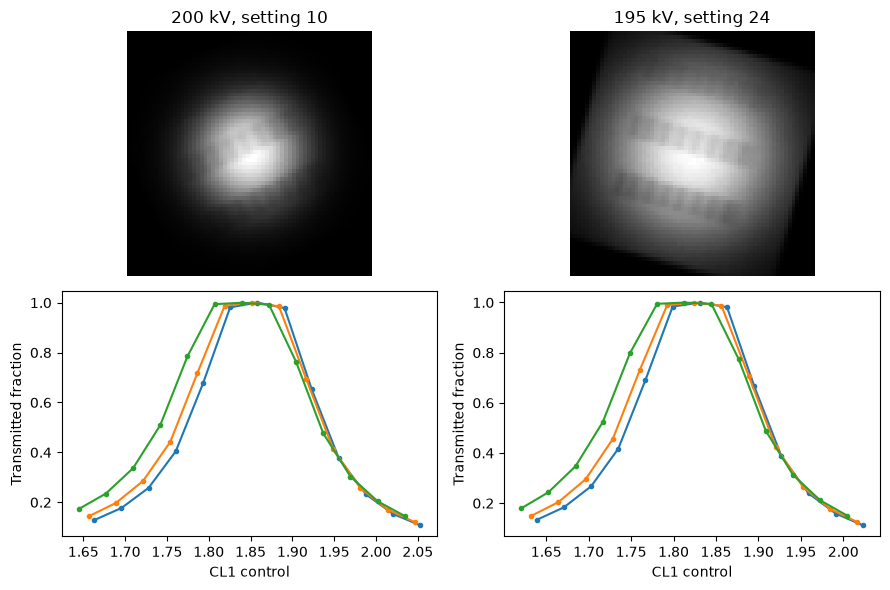

In [2]:
measurements = prepare_measurements(
    protocol_path=protocol,
    projector_views_path=projector_calibration,
    voltages_v=(200_000, 195_000),
    view_indices=(0, 1, 2),
    centre_aperture=True,
    output_directory=results / "voltage_01",
    random_seed=18101,
    reuse_completed=reuse_completed,
)
show_experiment(measurements_directory=measurements);

## 2. Fit an unknown microscope

**Supply:** the measured beams and currents, engineering bounds and starting guesses. **Get:** every attempted fit, its error and its geometry. There are no soft priors.

The ray order is $[x,y,\theta_x,\theta_y,1]^T$:

$$
M=\begin{pmatrix}
A_{xx}&A_{xy}&B_{xx}&B_{xy}&d_x\\
A_{yx}&A_{yy}&B_{yx}&B_{yy}&d_y\\
C_{xx}&C_{xy}&D_{xx}&D_{xy}&g_x\\
C_{yx}&C_{yy}&D_{yx}&D_{yy}&g_y\\
0&0&0&0&1
\end{pmatrix}.
$$

Our centred solenoids have zero lens offsets; the source position and angles are unknown. The model transports the source mean and covariance and predicts the aperture current. Fitting minimises measurement residuals weighted by their covariance.

At fixed magnetic field, the solenoid strength scales with inverse electron momentum:

$$
q(V)=q(V_0)\sqrt{\frac{V_0(V_0+2mc^2/e)}{V(V+2mc^2/e)}}.
$$

All magnetic lenses see this change. Condenser currents compensate the upstream strength change; the objective current stays fixed. Source parameters remain free at each voltage. The known projector model is adjusted for the measured voltage. The fit includes the voltage correction as an unknown with its measured uncertainty. This calibration assumption is tested below. [Relativistic correction: JEOL](https://www.jeol.com/words/emterms/20121023.055258.php).

In [3]:
fitted = fit_geometry(
    measurements_directory=measurements,
    starting_guess_path=starting_guess,
    number_of_broad_starts=8,  # 12 initial guesses in total
    reuse_completed=reuse_completed,
)
print("Best fit RMS:", round(fitted["best_fit"]["residual_rms"], 3))

Best fit RMS: 0.964


## 3. Test how far the geometry can move

**Supply:** the measurements and fitted alternatives. **Get:** an interval for every lens position and thickness, both source waist positions, and the aperture position.

Fix one quantity, refit all others from two starts, and find where the fit becomes worse by $\Delta\chi^2=3.84$. This gives an individual 95% profile interval. Failed fits do not bound uncertainty. A finite search cannot prove global uniqueness. [Profile likelihood: Raue et al.](https://doi.org/10.1093/bioinformatics/btp358)

Compare the **full interval widths** with our provisional tolerances: 0.1 mm for lens/aperture axial positions, 5% for thicknesses, 1 mm for source position and 0.2 µm for aperture centre. Also compare the joint distance between acceptable aperture-centre solutions.

In [4]:
profiles = profile_geometry(
    measurements_directory=measurements,
    fitted=fitted,
    reuse_completed=reuse_completed,
)
intervals = finish_profile_intervals(
    measurements_directory=measurements,
    fitted=fitted,
    profiles=profiles,
    reuse_completed=reuse_completed,
)
geometry = show_profile_geometry(
    fitted=fitted,
    intervals=intervals,
    scoring_truth_path=measurements / "scoring_truth.json",  # scoring only
)

| Quantity | Fitted | 95% profile interval | Error from truth | Width meets tolerance? |
|---|---:|---|---:|---|
| source z mm | -324.963 | [-325.205, -324.722] | 0.0372 | True |
| CL1 z mm | -124.995 | [-125.024, -124.966] | 0.00482 | True |
| CL3 z mm | -84.9997 | [-85.0251, -84.9741] | 0.000324 | True |
| mini z mm | -25.0007 | [-25.0123, -24.989] | -0.000729 | True |
| prefield z mm | -2.49988 | [-2.50055, -2.49921] | 0.000115 | True |
| CL1 length mm | 4.98768 | [4.96327, 5.01219] | -0.0123 | True |
| CL3 length mm | 4.99984 | [4.99869, 5.00098] | -0.000162 | True |
| mini length mm | 3.00064 | [2.99698, 3.0043] | 0.000641 | True |
| prefield length mm | 0.997626 | [0.976074, 1.01901] | -0.00237 | True |
| aperture z mm | -79.9999 | [-80.0249, -79.9746] | 0.000139 | True |
| aperture x um | 0.0259147 | [0.0249775, 0.0268519] | 3.61e-05 | True |
| aperture y um | -0.0494276 | [-0.0503354, -0.0485198] | -0.000114 | True |
| source z second voltage mm | -325.013 | [-325.255, -324.772] | 0.0373 | True |

Initial guesses: 12. Acceptable fitted geometries agree within tolerances: True.


## 4. Repeat and challenge the result

**Supply:** the same procedure with fresh noise. **Get:** three complete acquisitions, analyses, fits and profile intervals. New lens settings provide 36 prediction images and 32 current readings per repetition. These are not used to fit the geometry.

Then hide a **20 V readback error**: the optics use 195,020 V while the recorded value is 195,000 V. Image analysis estimates the correction independently of the condenser model.

Hidden truth is used only for generation and scoring. Three repeats check stability but cannot establish 95% interval coverage. The calibration challenge still assumes the projector's magnetic response law is correct.

Residual RMS values near one mean errors comparable to the stated measurement uncertainty.

In [5]:
repetitions = run_robustness_checks(
    protocol_path=protocol,
    projector_views_path=projector_calibration,
    starting_guess_path=starting_guess,
    output_directory=results,
    seeds=(18101, 18121, 18141),
    voltages_v=(200_000, 195_000),
    centre_aperture=True,
    number_of_broad_starts=8,
    voltage_offset_v=20,
    reuse_completed=reuse_completed,
)
show_checks(profiles=profiles, repetitions=repetitions)

Profile points resolved: 77/78. Unfinished points do not bound uncertainty.


| Experiment | Fit RMS | Geometry meets tolerances? | Truth in profile 95% intervals | New-image RMS | New-current RMS |
|---|---:|---|---:|---:|---:|
| voltage_01 | 0.964 | True | 13/13 | 0.983 | 1.074 |
| voltage_02 | 0.979 | True | 13/13 | 0.982 | 0.908 |
| voltage_03 | 0.939 | True | 13/13 | 0.983 | 0.854 |
| voltage_readback_error | 0.959 | True | 13/13 | 0.986 | 1.001 |

These are individual profile intervals from a finite search. A few noise repeats cannot establish 95% coverage.


The decision is whether **all acceptable geometries found agree within the tolerances and survive noise and prediction checks**. Convergence frequency does not choose the correct solution.

The geometry describes the effective magnetic positions and lengths of this finite-solenoid model. Passing a synthetic test does not prove that a real lens has that field profile. The practical next check is aperture-motion repeatability; objective current remains fixed throughout.